# Explicación de algoritmos, ensamble y resultados

Este notebook presenta el fundamento de los métodos utilizados y relaciona sus mecanismos con los resultados del proyecto **Predicción del riesgo de incumplimiento en préstamos personales de Lending Club**. Complementa los notebooks 02, 03 y 04.

Los diagramas son esquemas conceptuales. Los porcentajes de sus ejemplos son **ilustrativos**; las tablas identificadas como resultados del proyecto se obtienen de los artefactos de la evaluación congelada. Estas celdas no entrenan modelos ni seleccionan nuevas configuraciones.

## 1. Problema y función de los modelos

Cada observación corresponde a un préstamo aceptado. La variable objetivo distingue `Charged Off = 1` de `Fully Paid = 0`; los demás estados no se consideran negativos. El modelo utiliza información de solicitud y bureau disponible bajo el supuesto de evaluación después de la verificación y antes del desembolso.

Su salida es una estimación de riesgo. Convertir esa estimación en una alerta requiere un **umbral**; no equivale automáticamente a rechazar una solicitud. La evaluación corresponde a préstamos con desenlace registrado y debe interpretarse junto con su cobertura.

Los cinco métodos reciben el mismo contrato de información. La referencia de 19 entradas se compara además con modelos que incorporan variables ampliadas y derivadas.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.build_explanation_notebook import draw_diagram, draw_results
OUT = ROOT / 'outputs'
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 30)
metrics = pd.read_csv(OUT/'final'/'metrics.csv')
selection = json.loads((OUT/'selection.json').read_text(encoding='utf-8'))
lock = json.loads((OUT/'selection_lock.json').read_text(encoding='utf-8'))

## 2. Regresión logística: una referencia lineal

La regresión logística combina las variables transformadas mediante coeficientes aprendidos. La puntuación lineal se convierte en probabilidad con la función logística:

$$z=\beta_0+\sum_j\beta_j x_j, \qquad p(y=1\mid x)=\frac{1}{1+e^{-z}}.$$

Un coeficiente positivo aumenta el **log-odds** de incumplimiento manteniendo las demás variables constantes; su significado depende de la transformación y de la escala. No debe interpretarse directamente como puntos porcentuales de riesgo ni como efecto causal.

**Implementación del proyecto.** Se ajustan imputación por mediana, indicadores de ausencia, estandarización y codificación one-hot usando únicamente entrenamiento. Se busca regularización mediante `C` y alternativas de ponderación de clases. El baseline conserva 19 entradas; la regresión ampliada utiliza el conjunto extendido.

**Ventaja:** referencia eficiente y relativamente interpretable. **Límite:** las interacciones y relaciones no lineales requieren transformaciones explícitas; los árboles pueden aprenderlas de manera más flexible.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


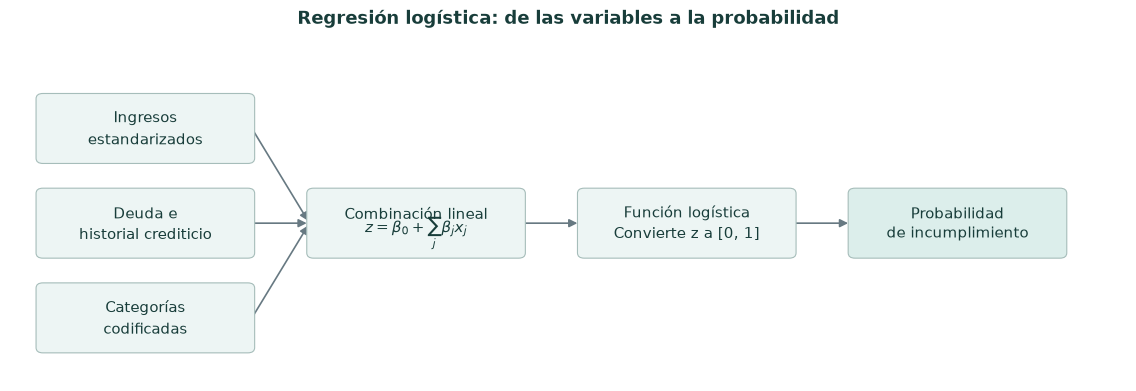

In [2]:
draw_diagram('logistic', OUT)

## 3. Random Forest: bagging y diversidad de árboles

### 3.1. Qué hace un árbol

Un árbol divide los datos mediante preguntas sucesivas sobre variables. Cada camino termina en una hoja, donde se estima la proporción de la clase positiva. Las variables, los cortes y los caminos del esquema siguiente son ilustrativos; no son reglas extraídas del modelo final.

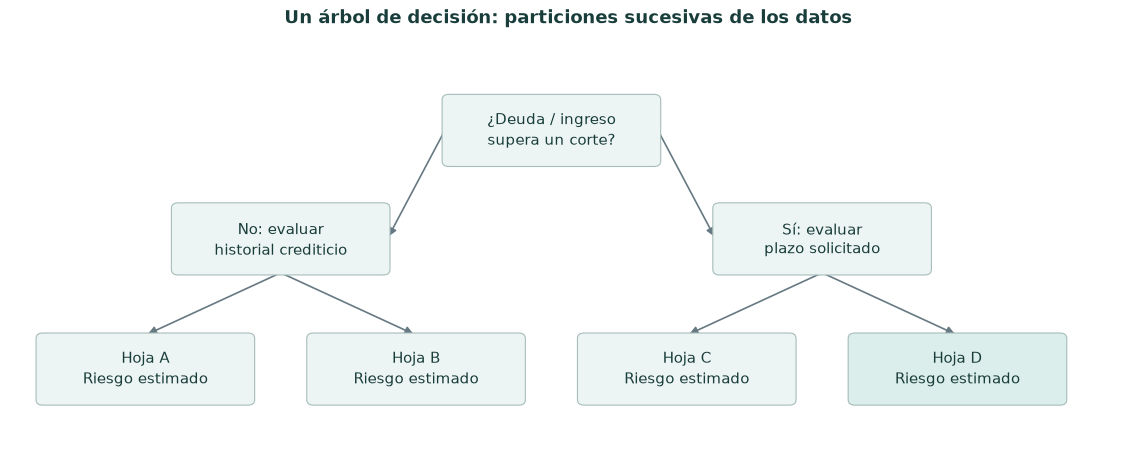

In [3]:
draw_diagram('tree', OUT)

### 3.2. Cómo se forma el bosque

Random Forest entrena árboles sobre muestras bootstrap y considera subconjuntos aleatorios de variables en sus divisiones. La diversidad reduce la dependencia de un único árbol. En clasificación probabilística se promedian sus estimaciones:

$$p_{RF}(x)=\frac{1}{T}\sum_{t=1}^{T}p_t(x).$$

Los árboles no corrigen secuencialmente los errores del árbol anterior: se ajustan por separado y comparten los datos de origen. Su aleatoriedad no implica independencia estadística perfecta.

**Implementación del proyecto.** Imputación, indicadores de ausencia y one-hot; representación densa float32. La búsqueda utilizó submuestras de hasta 30.000/20.000 filas por corte y 120 árboles por su costo computacional. La selección posterior y el ajuste definitivo utilizaron todas las filas correspondientes y 250 árboles. Se controlaron profundidad, tamaño mínimo de hoja, muestreo de filas y variables.

**Ventaja:** aprende interacciones y relaciones no lineales. **Límite:** puede ser costoso y sus probabilidades pueden requerir calibración.

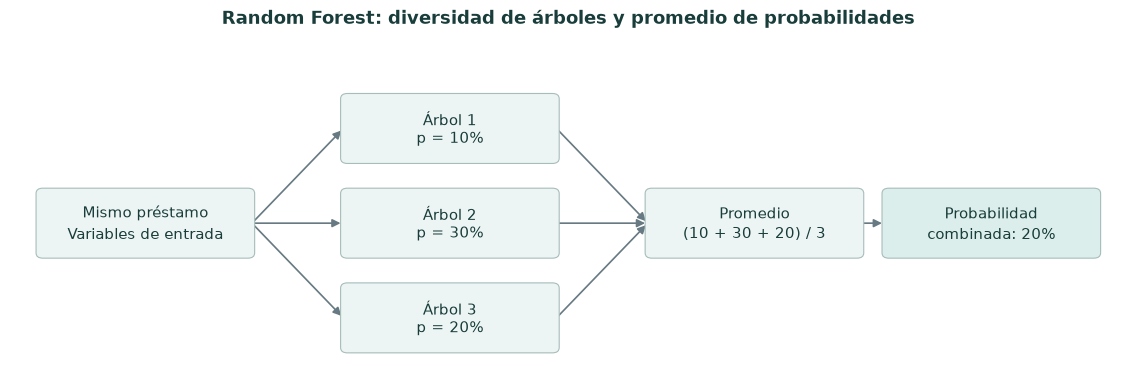

In [4]:
draw_diagram('forest', OUT)

## 4. XGBoost: boosting regularizado

XGBoost construye un modelo aditivo de árboles. Cada nuevo árbol utiliza información de los gradientes de la función de pérdida para mejorar el conjunto existente. Para clasificación binaria, una forma esquemática es:

$$F_t(x)=F_{t-1}(x)+\eta f_t(x),\qquad p(x)=\sigma(F_T(x)).$$

`η` es la tasa de aprendizaje; `f_t` es la aportación del nuevo árbol. Las correcciones se acumulan en la puntuación interna, **no sumando directamente porcentajes de probabilidad**. La regularización y los controles de complejidad penalizan soluciones excesivamente flexibles.

**Implementación del proyecto.** Se utilizó `hist` en CPU, valores numéricos ausentes nativos y categorías codificadas con entrenamiento y declaradas como categóricas al algoritmo. Las categorías nuevas se convierten en ausentes. Se ajustaron profundidad, regularización, tasa de aprendizaje y muestreo. El early stopping se aplicó dentro de las validaciones de desarrollo.

**Ventaja:** flexibilidad y controles de regularización. **Límite:** sensibilidad a la configuración y mayor complejidad interpretativa que un modelo lineal.

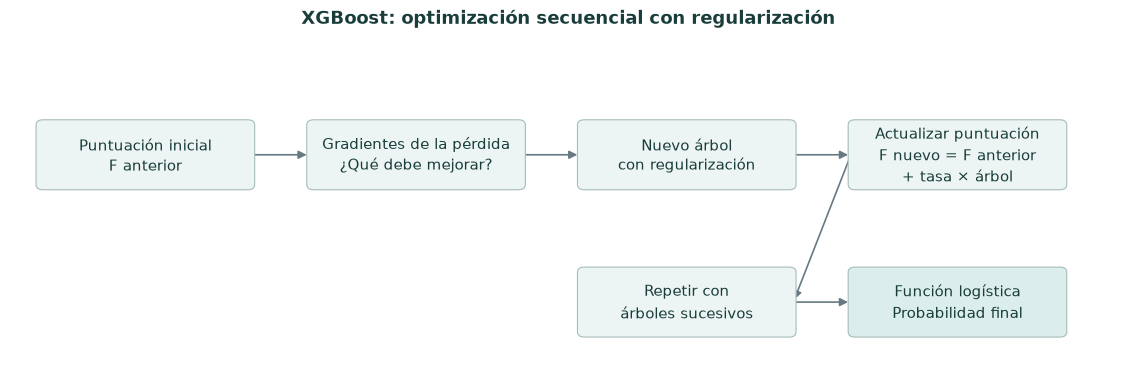

In [5]:
draw_diagram('xgboost', OUT)

## 5. LightGBM: histogramas y crecimiento leaf-wise

LightGBM también es gradient boosting con árboles. Los histogramas agrupan valores numéricos en intervalos para reducir el costo de buscar cortes. Su crecimiento habitual divide la hoja cuya división ofrece mayor ganancia, en lugar de exigir un crecimiento uniforme por niveles.

Este crecimiento permite ajustar relaciones complejas, pero requiere limitar hojas y exigir suficientes observaciones por hoja para controlar sobreajuste. La ganancia se calcula a partir del objetivo de entrenamiento; no es simplemente la cantidad de errores de clasificación.

**Implementación del proyecto.** Se emplearon numéricas con ausentes nativos y categorías codificadas en entrenamiento y declaradas categóricas. Se buscaron número de hojas, tamaño mínimo de hoja, tasa de aprendizaje, regularización y muestreo. La configuración seleccionada utiliza 143 árboles y hasta 28 hojas por árbol.

**Ventaja:** eficiencia en datos tabulares. **Límite:** una estructura demasiado flexible puede sobreajustar; velocidad y calidad dependen de los datos y de la configuración.

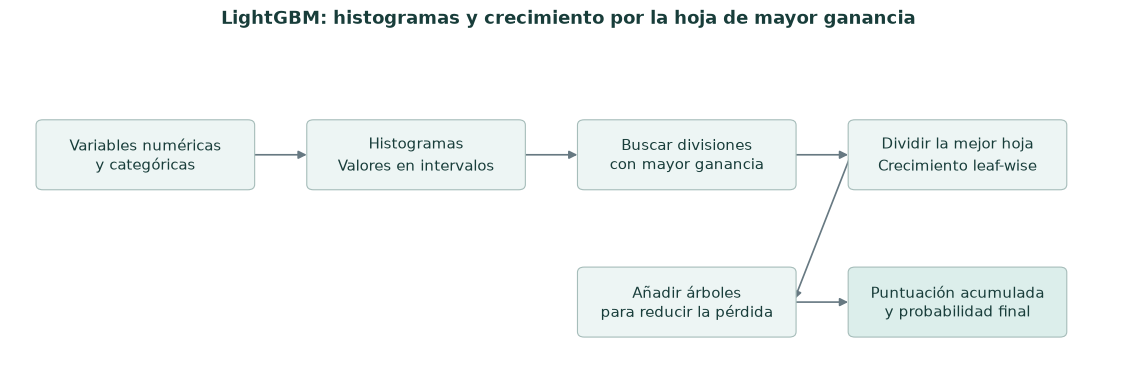

In [6]:
draw_diagram('lightgbm', OUT)

## 6. CatBoost: categorías y árboles simétricos

CatBoost es otra implementación de boosting. Se distingue por su tratamiento de variables categóricas mediante representaciones aprendidas, incluidas estadísticas construidas con mecanismos que evitan usar directamente la etiqueta de la propia fila. También utiliza variables numéricas.

Sus árboles simétricos habituales aplican la misma regla de división a todos los nodos de un nivel, lo que produce una estructura regular. Este rasgo es distinto del crecimiento leaf-wise descrito para LightGBM.

**Implementación del proyecto.** Se conservaron las categorías como texto. Se utilizó `boosting_type='Plain'`, con estadísticas categóricas y complejidad de combinaciones limitada. El modo Plain no equivale al algoritmo de ordered boosting descrito en la literatura; tampoco elimina el tratamiento categórico propio de CatBoost. La configuración seleccionada utiliza 740 árboles, profundidad 7 y regularización.

**Ventaja:** integración de variables numéricas y categóricas. **Límite:** mayor tiempo de ajuste en este equipo y necesidad de explicación posterior. Que resultara el mejor modelo individual aquí es un resultado empírico, no una propiedad garantizada.

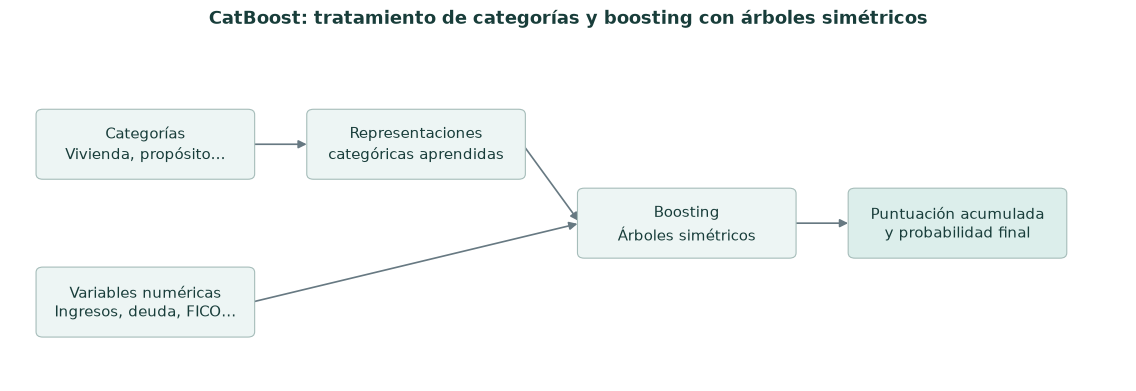

In [7]:
draw_diagram('catboost', OUT)

## 7. Diferencias principales

| Método | Estructura del aprendizaje | Tratamiento empleado en el proyecto |
|---|---|---|
| Regresión logística | Combinación lineal y función logística | Imputación, escalado y one-hot |
| Random Forest | Árboles ajustados por separado y promediados | Bagging y selección aleatoria de variables |
| XGBoost | Árboles sucesivos con objetivo regularizado | Histogramas y categorías nativas declaradas |
| LightGBM | Árboles sucesivos con crecimiento leaf-wise | Histogramas y controles de hojas |
| CatBoost | Árboles sucesivos, simétricos por defecto | Tratamiento propio de categorías |

XGBoost, LightGBM y CatBoost pertenecen a la familia de gradient boosting. Comparten varios recursos, como regularización y manejo de ausentes; la tabla destaca diferencias relevantes, no capacidades exclusivas de cada biblioteca.

## 8. Ensamble: combinar predicciones de modelos completos

Los modelos se entrenan por separado y reciben el mismo préstamo al predecir. No se unen sus árboles ni se utiliza la predicción de CatBoost como una nueva variable de LightGBM. Se realiza un **promedio ponderado de probabilidades**, también llamado blending o soft voting ponderado.

En cada familia se promedian tres semillas:

$$\bar p_C(x)=\frac{p_{C,42}(x)+p_{C,43}(x)+p_{C,44}(x)}{3},\qquad
\bar p_L(x)=\frac{p_{L,42}(x)+p_{L,43}(x)+p_{L,44}(x)}{3}.$$

Después se combinan las familias:

$$p_{mezcla}(x)=0.60\bar p_C(x)+0.40\bar p_L(x).$$

Por tanto, cada CatBoost tiene peso 0,20 y cada LightGBM peso aproximado 0,1333. Las semillas generan variaciones del entrenamiento; no son nuevas poblaciones ni garantizan independencia de errores. El promedio busca reducir variación y aprovechar diferencias entre modelos.

Los pesos se buscaron en incrementos de 0,1 utilizando **2014 H1**, antes de abrir la prueba. El protocolo exigía al menos 0,001 AP de mejora respecto al mejor modelo individual. La AP de selección fue 0,3401 para el ensamble y 0,3387 para el mejor individual. La diferencia es pequeña, aunque cumplió la regla fijada; el costo incluye mantener seis modelos.

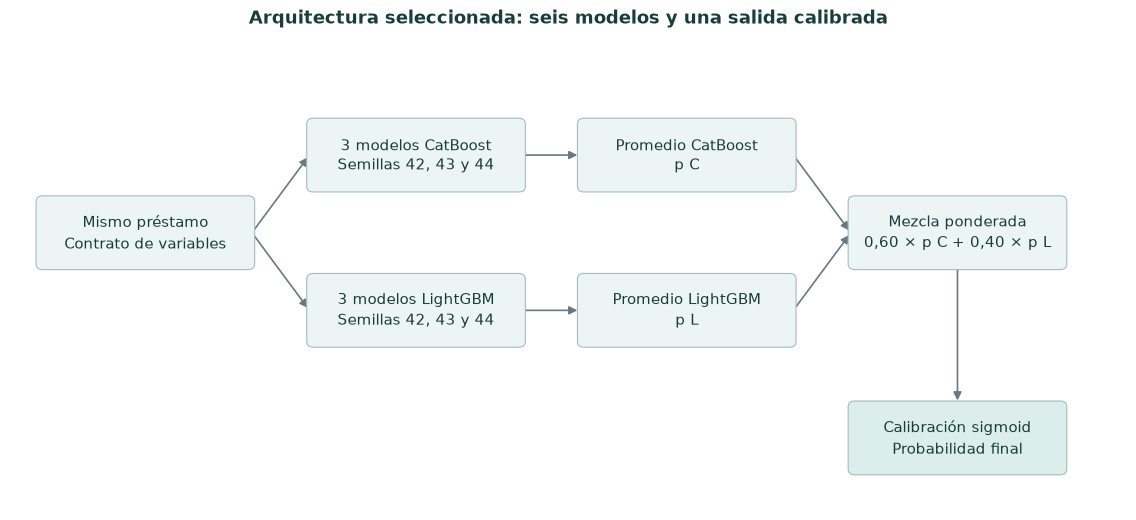

,componente,peso
0,catboost,0.200000
1,catboost_seed43,0.200000
2,catboost_seed44,0.200000
3,lightgbm,0.133333
4,lightgbm_seed43,0.133333
5,lightgbm_seed44,0.133333


In [8]:
draw_diagram('ensemble', OUT)
display(pd.DataFrame([{'componente': k, 'peso': v} for k,v in selection['weights'].items()]))

### 8.1. Ejemplo numérico ilustrativo

Supongamos que el promedio de CatBoost estima 30% y el promedio de LightGBM 20%. La combinación sin calibrar es `0,60 × 0,30 + 0,40 × 0,20 = 0,26`, es decir, 26%.

El 60% y el 40% indican **influencia sobre el promedio**. No indican precisión, porcentaje de datos utilizados, proporción de préstamos incumplidos ni porcentaje de árboles que aciertan.

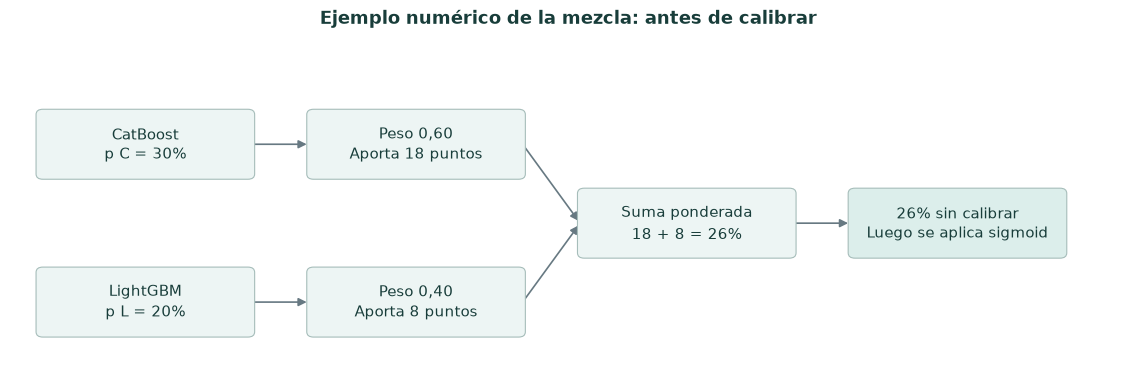

Ejemplo ilustrativo: probabilidad mezclada sin calibrar = 26.0%


In [9]:
draw_diagram('blend_example', OUT)
p_cat, p_light = 0.30, 0.20
p_blend = 0.60*p_cat + 0.40*p_light
print(f'Ejemplo ilustrativo: probabilidad mezclada sin calibrar = {p_blend:.1%}')

### 8.2. De la mezcla a la probabilidad calibrada y a la alerta

El proyecto compara identidad, sigmoid e isotonic. Los calibradores se ajustan en **2014 Q3** y el método se elige por Brier en **2014 Q4**. El elegido para el ensamble fue sigmoid. Su forma es:

$$p_{final}(x)=\sigma\!\left(a\,\operatorname{logit}(p_{mezcla}(x))+b\right).$$

`a` y `b` se aprenden en calibración. Así, **26% antes de calibrar no tiene por qué ser 26% después de calibrar**. La calibración intenta acercar las probabilidades a frecuencias observadas; no garantiza que sigan calibradas en otro año.

Después se compara `p_final` con un umbral fijado en desarrollo para producir una alerta. El umbral de F1 del ensamble es aproximadamente **0,2085**. La clasificación por umbral y la selección del 20% de mayor riesgo son políticas distintas; sus métricas no deben mezclarse.

In [10]:
print('Calibración del ensamble:', lock['calibration']['selected'])
print('Umbrales fijados antes de probar:', lock['thresholds']['selected'])

Calibración del ensamble: sigmoid
Umbrales fijados antes de probar: {'f1': 0.20848339818594064, 'recall60': 0.22052834830194312, 'capacity20': 0.29947155592004093, 'default': 0.5}


## 9. Evaluación temporal y procedencia de los datos

El archivo original contiene 2.260.701 registros, pero no todos se utilizan para entrenar. El modelo definitivo se ajustó con **327.426 préstamos hasta junio de 2014**. Los bloques posteriores de 2014 se reservaron para calibración y política de umbral.

Las pruebas incluyen **343.507 préstamos de 2015** y **268.096 de 2016**, con IDs ajenos a la muestra inicial de 115.000 y exclusiones adicionales documentadas por inspección de esquema. La búsqueda utiliza dos validaciones crecientes de 2012/2013; la selección de modelos y pesos utiliza 2014 H1.

Se congelaron modelo, calibradores, umbrales y huellas de código/datos antes de abrir los desenlaces externos. Se trata de nuevas cohortes de la **misma fuente**, no de validación en otra institución o país.

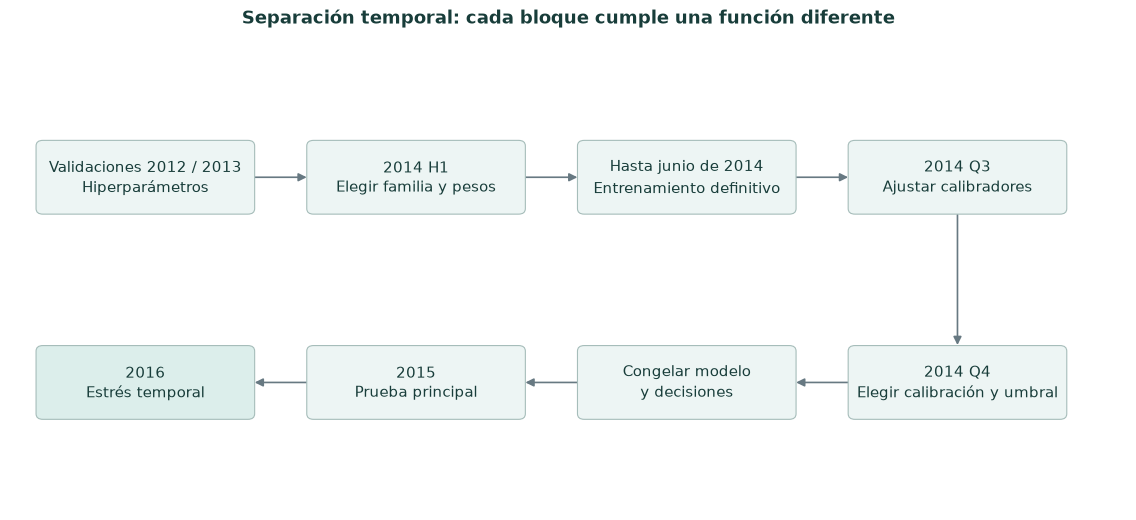

In [11]:
draw_diagram('protocol', OUT)

## 10. Resultados reales del experimento

La tabla siguiente corresponde a **2015, todos los resultados terminales**, y utiliza las mismas filas para todos los comparadores. `baseline19` es la referencia logística balanceada reentrenada bajo el nuevo protocolo; `logistic` es la regresión con variables ampliadas. No debe confundirse esta comparación con la AP 0,3610 del avance inicial, que pertenecía a otra partición.

Cada comparador fue calibrado con el mismo esquema temporal. Las métricas de umbral usan el umbral propio fijado en desarrollo. El ganador sigue siendo el seleccionado antes de probar; no se reelige usando esta tabla.

In [12]:
names={'baseline19':'Referencia logística (19 entradas)','logistic':'Regresión logística ampliada','random_forest':'Random Forest','lightgbm':'LightGBM','xgboost':'XGBoost','catboost':'CatBoost','selected':'Ensamble seleccionado'}
comparison=metrics.query("cohort == 2015 and scope == 'all_resolved'").copy()
comparison['modelo']=comparison.model.map(names)
display(comparison[['modelo','AP','ROC_AUC','Brier','precision','recall','F1']].round(4))
base=comparison.set_index('model').loc['baseline19']
chosen=comparison.set_index('model').loc['selected']
print(f'Mejora de AP: {chosen.AP-base.AP:+.4f}; de ROC-AUC: {chosen.ROC_AUC-base.ROC_AUC:+.4f}.')

,modelo,AP,ROC_AUC,Brier,precision,recall,F1
0,Referencia logística (19 entradas),0.3890,0.7111,0.1455,0.3509,0.5653,0.4330
3,Regresión logística ampliada,0.4021,0.7264,0.1432,0.3558,0.5969,0.4458
6,Random Forest,0.4006,0.7212,0.1439,0.3707,0.5320,0.4370
9,LightGBM,0.4117,0.7304,0.1424,0.3585,0.6001,0.4489
12,XGBoost,0.4115,0.7300,0.1424,0.3614,0.5911,0.4486
15,CatBoost,0.4145,0.7326,0.1420,0.3477,0.6374,0.4499
18,Ensamble seleccionado,0.4164,0.7334,0.1418,0.3556,0.6158,0.4509


Mejora de AP: +0.0274; de ROC-AUC: +0.0224.


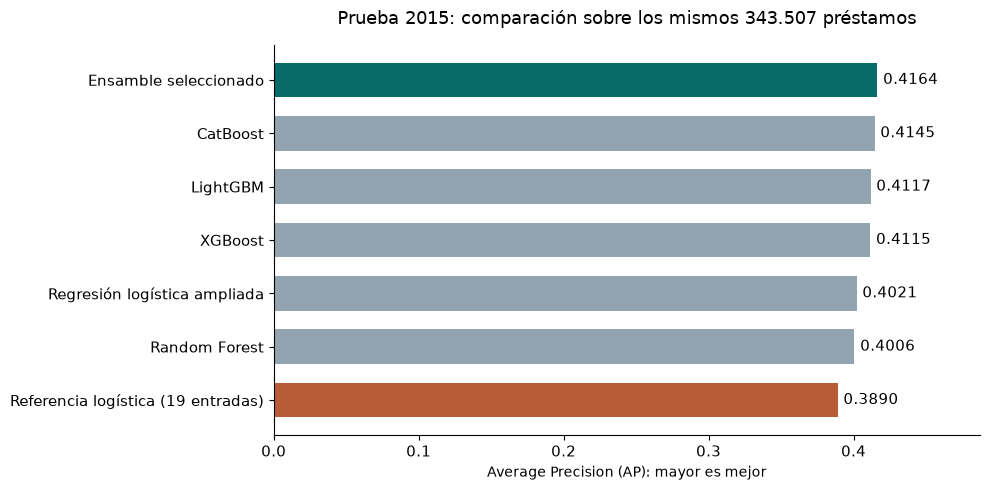

In [13]:
draw_results(comparison, OUT)

### 10.1. Qué significa ROC-AUC = 0,7334

Mide discriminación: la capacidad de ordenar positivos por encima de negativos. Si se elige aleatoriamente un préstamo incumplido y uno pagado, el valor equivale a una probabilidad aproximada de **73,3%** de asignar mayor puntuación al incumplido, contando los empates con peso medio.

No significa 73,3% de exactitud, de incumplimientos detectados ni de probabilidades correctas. Una ROC-AUC de 0,5 representa un ordenamiento sin capacidad de discriminación; 1 representa discriminación perfecta.

### 10.2. Qué significa AP = 0,4164

Average Precision resume la precisión conseguida a medida que se recuperan más incumplimientos al variar el umbral. Se calcula como una media de precisiones ponderada por los incrementos de recall. En este proyecto se usa `average_precision_score`, **no integración trapezoidal de la curva PR**.

La prevalencia de incumplimiento de 2015 es aproximadamente 20,14%, referencia de un ordenamiento aleatorio en una población grande. La AP depende de esa prevalencia, por lo que no conviene comparar directamente AP de años o plazos con composiciones distintas.

AP 0,4164 no equivale a 41,64% de aciertos ni a la precisión de un único umbral. La mejora pareada frente al baseline es +0,0274; el intervalo bootstrap del 95% por bloques mensuales es aproximadamente [+0,0243; +0,0302]. Solo hay 12 bloques: ese intervalo no recoge toda la incertidumbre macroeconómica o institucional.

### 10.3. Qué significa en una revisión de préstamos

Al ordenar los préstamos de 2015 y revisar el 20% de mayor riesgo, se recupera aproximadamente **42,5% de los incumplimientos**. Dentro de ese grupo, aproximadamente **42,8% incumplió**. Como ilustración proporcional, entre 100 préstamos con unos 20 incumplimientos, revisar los 20 de mayor riesgo permitiría encontrar alrededor de 9, frente a unos 4 al elegirlos al azar.

Con el umbral F1 fijado en desarrollo se obtiene otro compromiso: **precisión 35,6% y recall 61,6%**. Esta política genera una cantidad de alertas distinta de revisar exactamente el 20%.

In [14]:
print('Cohorte 2015:', int(chosen.n), 'préstamos')
print(f'Prevalencia: {chosen.prevalence:.2%}')
print(f'Recall entre el 20% de mayor riesgo: {chosen.recall_at_top20:.2%}')
print(f'Precisión entre el 20% de mayor riesgo: {chosen.precision_at_top20:.2%}')
print(f'Umbral F1: {chosen.threshold:.4f}; precisión: {chosen.precision:.2%}; recall: {chosen.recall:.2%}')
records=json.loads((OUT/'final'/'metrics.json').read_text(encoding='utf-8'))
record=next(r for r in records if r['cohort']==2015 and r['scope']=='all_resolved' and r['model']=='selected')
display(pd.DataFrame(record['confusion_matrix'],index=['Real pagado','Real incumplido'],columns=['Sin alerta','Con alerta']))

Cohorte 2015: 343507 préstamos
Prevalencia: 20.14%
Recall entre el 20% de mayor riesgo: 42.52%
Precisión entre el 20% de mayor riesgo: 42.82%
Umbral F1: 0.2085; precisión: 35.56%; recall: 61.58%


,Sin alerta,Con alerta
Real pagado,197086,77222
Real incumplido,26585,42614


## 11. Estabilidad, interpretación y límites

El ensamble obtuvo la mayor AP y ROC-AUC entre los comparadores congelados en 2015 y 2016. Eso no implica que todas sus métricas sean las mejores ni que sea el mejor modelo posible fuera del experimento.

**Calibración temporal.** En 2016 el riesgo medio predicho fue aproximadamente 18,0%, frente a 23,3% observado entre préstamos con resultado terminal. La capacidad de ordenar riesgos puede mantenerse mientras las probabilidades subestiman su nivel.

**Maduración y censura.** En 2015, 99,94% de los préstamos elegibles a 36 meses tienen resultado terminal; a 60 meses, solo 65,09%. Excluir los todavía vigentes puede sesgar los resultados agregados. La mejora se mantiene en la prueba de 2015 a 36 meses: AP del ensamble 0,2718 frente a 0,2386 del baseline.

**Disponibilidad histórica de etiquetas.** El corte se hace por emisión, pero el snapshot no permite reconstruir fiablemente cuándo se conoció cada incumplimiento. Es una evaluación retrospectiva, no un backtest exacto de producción.

**Interpretabilidad.** La permutación por grupos explica la dependencia predictiva del ensamble; destacan monto/plazo, ingresos y FICO. Tree SHAP explica sus componentes en log-odds. Esas contribuciones no se suman directamente como porcentajes de la probabilidad calibrada final. Ninguna de estas técnicas demuestra causalidad.

**Población y equidad.** No se evalúan solicitantes rechazados, todos los préstamos vigentes ni otra institución. Los diagnósticos por segmentos no certifican equidad en ausencia de atributos protegidos.

**Implicación.** La mejora apoya la utilidad del enfoque para investigación y priorización experimental de revisiones. El uso operativo requiere seguimiento completo, nuevas pruebas, calibración vigente y evaluación de costos y disparidades.

In [15]:
display(metrics.query("model in ['baseline19','selected']")[[ 'cohort','scope','model','n','prevalence','AP','ROC_AUC','Brier']].round(4))
display(pd.read_csv(OUT/'final'/'maturity_coverage.csv'))

,cohort,scope,model,n,prevalence,AP,ROC_AUC,Brier
0,2015,all_resolved,baseline19,343507,0.2014,0.3890,0.7111,0.1455
1,2015,36_month,baseline19,258856,0.1486,0.2386,0.6579,0.1217
2,2015,60_month,baseline19,84651,0.3630,0.4999,0.6530,0.2185
18,2015,all_resolved,selected,343507,0.2014,0.4164,0.7334,0.1418
19,2015,36_month,selected,258856,0.1486,0.2718,0.6920,0.1190
20,2015,60_month,selected,84651,0.3630,0.5315,0.6785,0.2116
21,2016,all_resolved,baseline19,268096,0.2327,0.3958,0.6875,0.1678
22,2016,36_month,baseline19,212482,0.1984,0.3143,0.6647,0.1545
23,2016,60_month,baseline19,55614,0.3638,0.5068,0.6600,0.2186
39,2016,all_resolved,selected,268096,0.2327,0.4248,0.7116,0.1631


,year,term,external_population_n,resolved_n,excluded_nonterminal_n,terminal_fraction
0,2015,36 months,259003,258856,147,0.999432
1,2015,60 months,130054,84651,45403,0.650891
2,2016,36 months,303624,212482,91142,0.699820
3,2016,60 months,105784,55614,50170,0.525732


## 12. Síntesis para la exposición

> Se comparó una referencia lineal, un método de bagging y tres implementaciones de gradient boosting. Se seleccionó mediante validación temporal un promedio de probabilidades de CatBoost y LightGBM, con pesos 60/40 y tres semillas por familia. Tras congelar el predictor y calibrarlo con datos de desarrollo, la prueba de 2015 mostró AP 0,4164 y ROC-AUC 0,7334, superiores a la referencia reentrenada sobre las mismas filas. El análisis también identificó subestimación de riesgo en 2016 y límites de censura, disponibilidad histórica de etiquetas y generalización.

### Referencias y trazabilidad

- [Artículos y decisiones metodológicas](../experiments/research_notes.md).
- [Protocolo fijado antes de probar](../experiments/protocol.json).
- [Comparación experimental completa](03_modelos.ipynb).
- [Análisis de errores e interpretabilidad](04_analisis_errores.ipynb).
- [Métricas de la prueba](../outputs/final/metrics.csv) y [congelación del experimento](../outputs/selection_lock.json).

Para regenerar únicamente este material desde la raíz del repositorio: `python scripts/build_explanation_notebook.py`. Solo lee resultados ya guardados y genera diagramas; no vuelve a ajustar ni evaluar los modelos.